<a href="https://colab.research.google.com/github/venkatasai-eng/Computer-Vision/blob/main/Exp29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving man.avif to man (1).avif


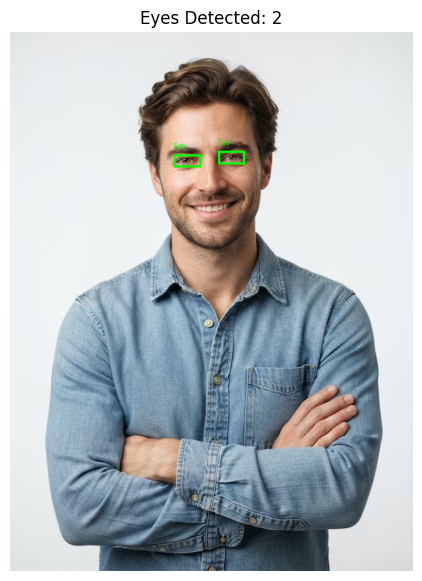

Number of eyes detected: 2


In [2]:
!pip install -q mediapipe pillow pillow-avif-plugin

import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from google.colab import files
import urllib.request

# Download face landmark model
url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
urllib.request.urlretrieve(url, "face_landmarker.task")

# Upload image
uploaded = files.upload()
filename = next(iter(uploaded))

import pillow_avif
img = Image.open(filename).convert("RGB")
image = np.array(img)

# Initialize face detector
options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path="face_landmarker.task"
    ),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=10
)

# Eye landmark indices
eye_indices = [
    [33, 133, 159, 145, 153, 154, 155, 173, 157, 158, 160, 161, 246],
    [362, 263, 386, 374, 380, 381, 382, 398, 384, 385, 387, 388, 466]
]

output = img.copy()
draw = ImageDraw.Draw(output)
count = 0

with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=image
    )
    results = detector.detect(mp_image)

    for face in results.face_landmarks:
        for indices in eye_indices:
            points = [
                (int(face[i].x * img.width),
                 int(face[i].y * img.height))
                for i in indices
            ]

            x1 = max(0, min(p[0] for p in points) - 5)
            y1 = max(0, min(p[1] for p in points) - 5)
            x2 = min(img.width, max(p[0] for p in points) + 5)
            y2 = min(img.height, max(p[1] for p in points) + 5)

            draw.rectangle(
                (x1, y1, x2, y2),
                outline="lime",
                width=3
            )
            draw.text((x1, max(0, y1 - 18)), "Eye", fill="lime")
            count += 1

plt.figure(figsize=(10, 7))
plt.imshow(output)
plt.title(f"Eyes Detected: {count}")
plt.axis("off")
plt.show()

print("Number of eyes detected:", count)